# LSTM Forecast: USD/EUR

Notebook นี้สร้างตาม evaluation flow ที่กำหนดไว้:

1. ตรวจและ clean ข้อมูลเท่าที่จำเป็น โดยเก็บข้อมูลดิบไว้เหมือนเดิม
2. เปรียบเทียบ chronological split แบบ **80/20** และ **70/15/15**
3. ทำ **3-fold expanding-window cross-validation** ภายใน training data
4. ตรวจ diagnostics/assumptions ที่เหมาะกับ LSTM
5. รายงาน error ทั้ง MAE, RMSE, MAPE และ sMAPE พร้อมเทียบ naive baseline

โจทย์ของโมเดลนี้คือใช้ราคา `LOOKBACK` วันที่ทราบแล้วเพื่อทำนายราคาวันถัดไปแบบ **rolling one-step-ahead** โดยไม่ shuffle ข้อมูล


In [1]:
# 1) Environment และ reproducibility
import os
import random
import warnings
from pathlib import Path

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from scipy.stats import jarque_bera, ttest_1samp
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
import statsmodels.api as sm

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

DATA_PATH = Path(
    r"C:\Users\User\Desktop\vs_nine\Project_stat\USD_EUR Historical Data.csv"
)

CV_SPLITS = 3
MAX_EPOCHS = 50
PATIENCE = 6
BATCH_SIZE = 32
EPSILON = 1e-12

print("TensorFlow:", tf.__version__)
print("Devices:", tf.config.list_physical_devices())


TensorFlow: 2.21.0


Devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


## 2) Data cleansing

หลักการคือแก้เฉพาะปัญหาที่มีเหตุผลรองรับ ไม่เติมวันเสาร์–อาทิตย์และไม่ลบ price spikes ที่อาจเป็นเหตุการณ์ตลาดจริง ส่วน `Vol.` จะไม่ใช้เพราะ missing เป็นสัดส่วนสูงมาก


In [2]:
raw_df = pd.read_csv(DATA_PATH)
df = raw_df.copy()

# Parse date และ numeric fields
df["Date"] = pd.to_datetime(
    df["Date"],
    format="%m/%d/%Y",
    errors="coerce",
)

ohlc_columns = ["Price", "Open", "High", "Low"]
for column in ohlc_columns:
    df[column] = pd.to_numeric(
        df[column].astype(str).str.replace(",", "", regex=False),
        errors="coerce",
    )

df["Change_pct"] = pd.to_numeric(
    df["Change %"].astype(str).str.replace("%", "", regex=False),
    errors="coerce",
) / 100

# เก็บตัวเลขคุณภาพข้อมูลก่อน clean
invalid_dates = int(df["Date"].isna().sum())
duplicate_dates = int(df["Date"].duplicated().sum())
missing_ohlc = int(df[ohlc_columns].isna().any(axis=1).sum())
missing_volume = int(df["Vol."].isna().sum())
nonpositive_rows = int((df[ohlc_columns] <= 0).any(axis=1).sum())

valid_high = df["High"] >= df[["Open", "Price", "Low"]].max(axis=1)
valid_low = df["Low"] <= df[["Open", "Price", "High"]].min(axis=1)
invalid_ohlc_rows = int((~(valid_high & valid_low)).sum())

# Clean เฉพาะ invalid/duplicate rows; ไม่แก้ไฟล์ raw
rows_before = len(df)
df = (
    df.dropna(subset=["Date", *ohlc_columns])
      .loc[lambda x: (x[ohlc_columns] > 0).all(axis=1)]
      .loc[
          lambda x: (
              (x["High"] >= x[["Open", "Price", "Low"]].max(axis=1))
              & (x["Low"] <= x[["Open", "Price", "High"]].min(axis=1))
          )
      ]
      .sort_values("Date")
      .drop_duplicates(subset="Date", keep="last")
      .reset_index(drop=True)
)

# Vol. ไม่ถูกใช้: missing สูงและไม่จำเป็นสำหรับ univariate LSTM
df = df.drop(columns=["Vol.", "Change %"])

# Flag outliers ด้วย robust z-score แต่ยังไม่ลบออก
df["log_return"] = np.log(df["Price"]).diff()
return_median = df["log_return"].median()
return_mad = (df["log_return"] - return_median).abs().median()

if return_mad > 0:
    df["return_robust_z"] = (
        0.6745 * (df["log_return"] - return_median) / return_mad
    )
else:
    df["return_robust_z"] = 0.0

df["possible_outlier"] = df["return_robust_z"].abs() > 6
possible_outliers = int(df["possible_outlier"].sum())

price = df.set_index("Date")["Price"].astype(float)

cleaning_report = pd.DataFrame({
    "Check": [
        "Raw rows",
        "Invalid dates",
        "Duplicate dates",
        "Rows with missing OHLC",
        "Rows with non-positive OHLC",
        "Rows with invalid OHLC relationship",
        "Missing Vol.",
        "Rows removed during cleaning",
        "Possible return outliers retained",
        "Final usable rows",
    ],
    "Value": [
        len(raw_df),
        invalid_dates,
        duplicate_dates,
        missing_ohlc,
        nonpositive_rows,
        invalid_ohlc_rows,
        missing_volume,
        rows_before - len(df),
        possible_outliers,
        len(price),
    ],
    "Action": [
        "reference",
        "drop if present",
        "keep last if present",
        "drop if present",
        "drop if present",
        "drop if present",
        "drop Vol. feature",
        "reported",
        "flag only; do not delete automatically",
        "model input",
    ],
})

display(cleaning_report)
print("Date range:", price.index.min().date(), "to", price.index.max().date())
print("Price missing after cleaning:", int(price.isna().sum()))


,Check,Value,Action
0,Raw rows,1044,reference
1,Invalid dates,0,drop if present
2,Duplicate dates,0,keep last if present
3,Rows with missing OHLC,0,drop if present
4,Rows with non-positive OHLC,0,drop if present
5,Rows with invalid OHLC relationship,0,drop if present
6,Missing Vol.,895,drop Vol. feature
7,Rows removed during cleaning,0,reported
8,Possible return outliers retained,0,flag only; do not delete automatically
9,Final usable rows,1044,model input


Date range: 2022-07-01 to 2026-07-01
Price missing after cleaning: 0


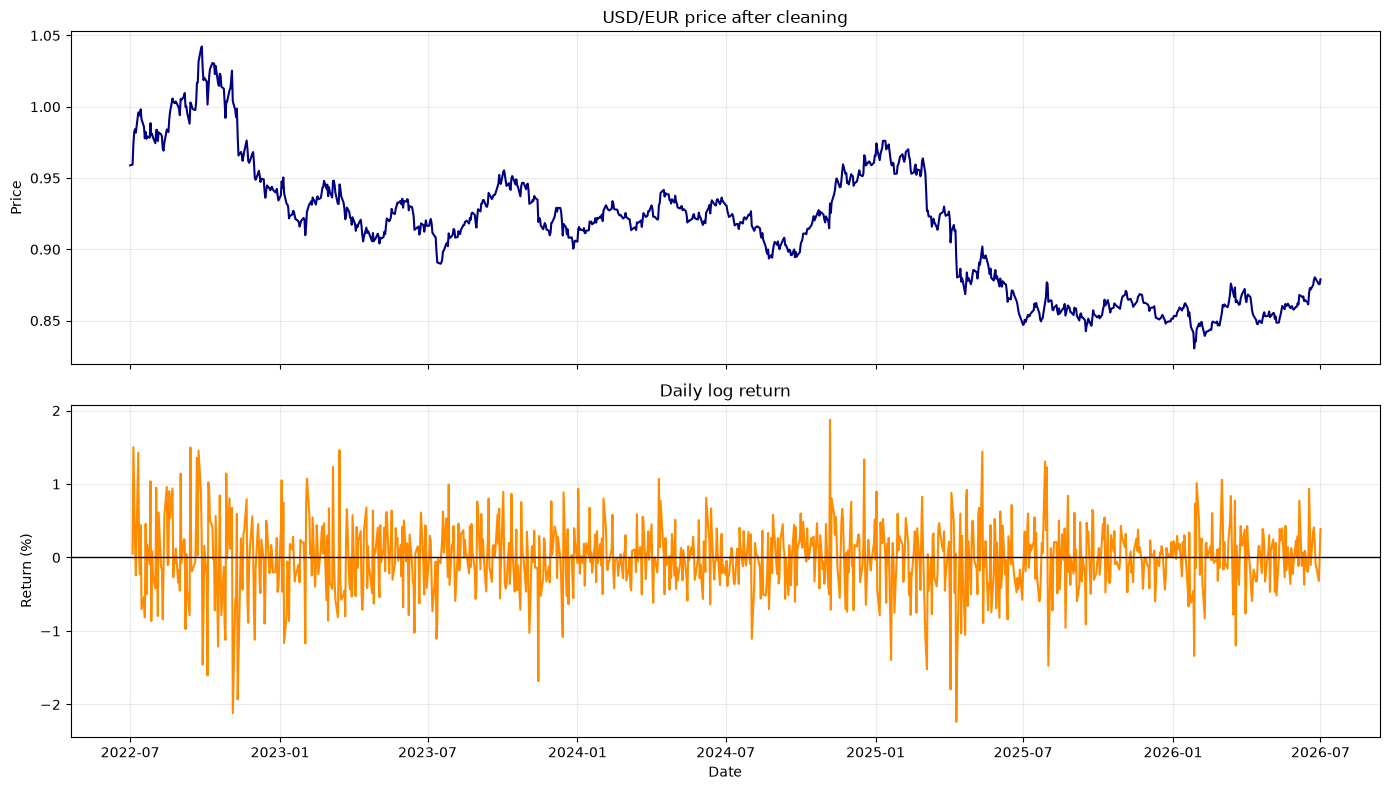

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

axes[0].plot(price.index, price, color="navy")
axes[0].set_title("USD/EUR price after cleaning")
axes[0].set_ylabel("Price")
axes[0].grid(alpha=0.25)

axes[1].plot(df["Date"], df["log_return"] * 100, color="darkorange")
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set_title("Daily log return")
axes[1].set_ylabel("Return (%)")
axes[1].set_xlabel("Date")
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()


## 3) Split 80/20 และ 70/15/15

ทุก split เรียงตามเวลาและไม่ shuffle ข้อมูล ช่วง test ของสองกลยุทธ์ไม่เท่ากัน จึงต้องแสดงวันที่และจำนวน observations ประกอบผล error


In [4]:
n = len(price)

# Strategy A: 80/20
split_80 = int(n * 0.80)
train_80 = price.iloc[:split_80]
test_20 = price.iloc[split_80:]

# Strategy B: 70/15/15
train_end_70 = int(n * 0.70)
validation_end_85 = int(n * 0.85)
train_70 = price.iloc[:train_end_70]
validation_15 = price.iloc[train_end_70:validation_end_85]
test_15 = price.iloc[validation_end_85:]

split_report = pd.DataFrame([
    {
        "Strategy": "80/20",
        "Train": len(train_80),
        "Validation": 0,
        "Test": len(test_20),
        "Test start": test_20.index.min().date(),
        "Test end": test_20.index.max().date(),
    },
    {
        "Strategy": "70/15/15",
        "Train": len(train_70),
        "Validation": len(validation_15),
        "Test": len(test_15),
        "Test start": test_15.index.min().date(),
        "Test end": test_15.index.max().date(),
    },
])

display(split_report)


,Strategy,Train,Validation,Test,Test start,Test end
0,80/20,835,0,209,2025-09-12,2026-07-01
1,70/15/15,730,157,157,2025-11-25,2026-07-01


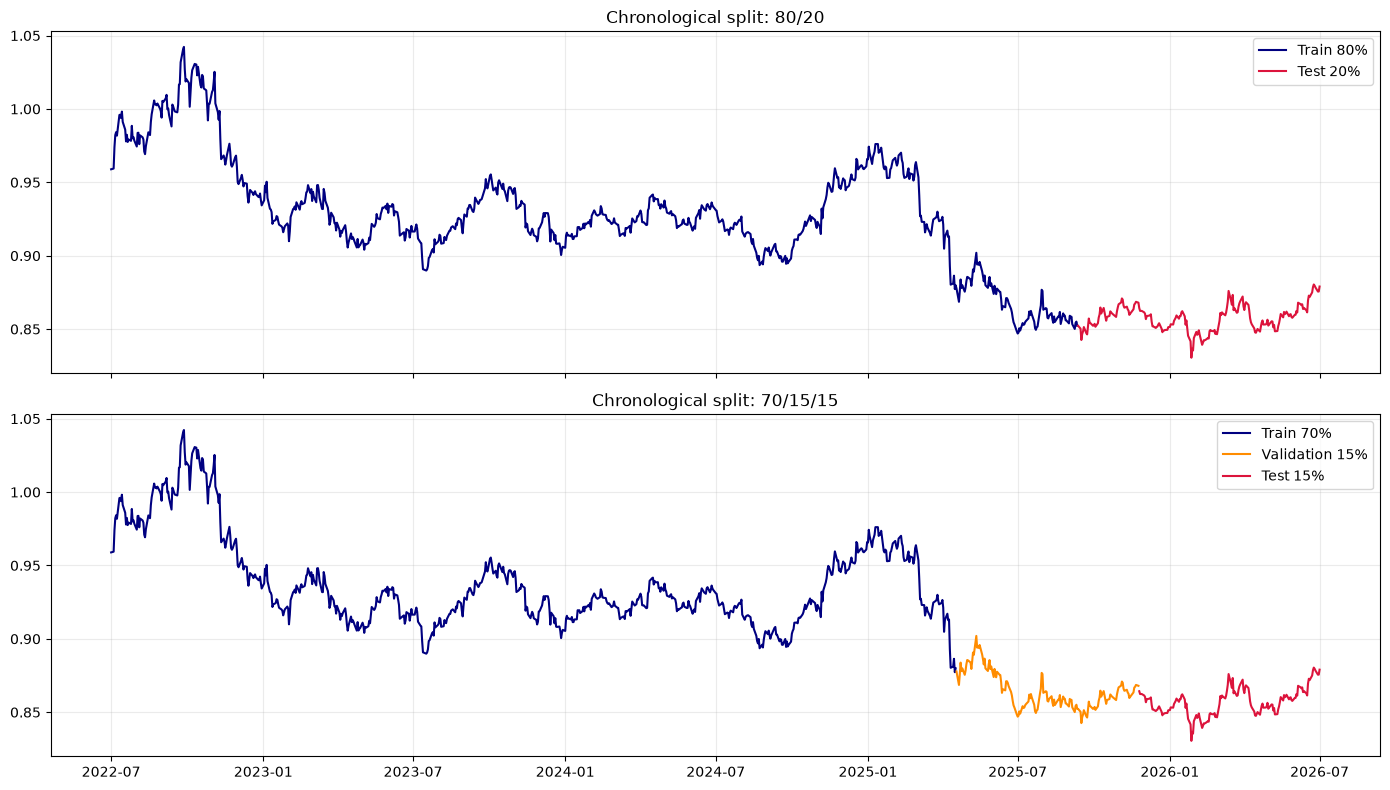

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

axes[0].plot(train_80.index, train_80, label="Train 80%", color="navy")
axes[0].plot(test_20.index, test_20, label="Test 20%", color="crimson")
axes[0].set_title("Chronological split: 80/20")
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].plot(train_70.index, train_70, label="Train 70%", color="navy")
axes[1].plot(
    validation_15.index,
    validation_15,
    label="Validation 15%",
    color="darkorange",
)
axes[1].plot(test_15.index, test_15, label="Test 15%", color="crimson")
axes[1].set_title("Chronological split: 70/15/15")
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()


## 4) LSTM helpers

Scaler จะ fit เฉพาะ training partition ของแต่ละ fold ส่วน validation/test sequences สามารถใช้ค่าจริงก่อนหน้าเป็น context ได้ เพราะเป็น rolling one-step-ahead evaluation


In [6]:
def make_train_sequences(scaled_values, lookback):
    values = np.asarray(scaled_values, dtype=np.float32).reshape(-1, 1)
    X, y = [], []

    for target_index in range(lookback, len(values)):
        X.append(values[target_index - lookback:target_index])
        y.append(values[target_index])

    return np.asarray(X), np.asarray(y)


def make_evaluation_sequences(
    training_scaled,
    evaluation_scaled,
    lookback,
):
    training_scaled = np.asarray(training_scaled).reshape(-1, 1)
    evaluation_scaled = np.asarray(evaluation_scaled).reshape(-1, 1)

    # ใช้ history ก่อน evaluation และค่าจริงก่อนหน้าภายใน evaluation
    combined = np.vstack([
        training_scaled[-lookback:],
        evaluation_scaled,
    ])
    X, y = make_train_sequences(combined, lookback)

    assert len(X) == len(evaluation_scaled)
    return X, y


def build_lstm_model(
    lookback,
    units,
    dropout=0.10,
    learning_rate=0.001,
    seed=SEED,
):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)

    model = Sequential([
        Input(shape=(lookback, 1)),
        LSTM(units),
        Dropout(dropout),
        Dense(1),
    ])
    model.compile(
        optimizer=Adam(learning_rate=learning_rate),
        loss="mse",
    )
    return model


def calculate_metrics(actual, predicted, previous_actual=None):
    actual = np.asarray(actual, dtype=float).reshape(-1)
    predicted = np.asarray(predicted, dtype=float).reshape(-1)
    error = actual - predicted

    metrics = {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "MAPE (%)": (
            np.mean(np.abs(error) / np.maximum(np.abs(actual), EPSILON))
            * 100
        ),
        "sMAPE (%)": (
            np.mean(
                2 * np.abs(error)
                / np.maximum(np.abs(actual) + np.abs(predicted), EPSILON)
            )
            * 100
        ),
    }

    if previous_actual is not None:
        previous_actual = np.asarray(previous_actual, dtype=float).reshape(-1)
        actual_direction = np.sign(actual - previous_actual)
        predicted_direction = np.sign(predicted - previous_actual)
        metrics["Direction accuracy (%)"] = (
            np.mean(actual_direction == predicted_direction) * 100
        )

    return metrics


def naive_one_step_forecast(train_series, test_series):
    return np.concatenate([
        [train_series.iloc[-1]],
        test_series.iloc[:-1].to_numpy(),
    ])


## 5) Expanding-window cross-validation

ทดลอง hyperparameters ขนาดเล็กให้เหมาะกับข้อมูลประมาณหนึ่งพัน observations:

- Lookback: 10, 20, 30 trading observations
- LSTM units: 16, 32
- Dropout: 0.10

80/20 ทำ CV ภายใน train 80% ส่วน 70/15/15 ทำ CV ภายใน train 70%; ไม่มี fold ใดเห็น final test


In [7]:
CV_CONFIGS = [
    {"lookback": lookback, "units": units, "dropout": 0.10}
    for lookback in [10, 20, 30]
    for units in [16, 32]
]


def fit_fold_and_evaluate(
    fold_train,
    fold_validation,
    config,
    seed,
):
    scaler = MinMaxScaler()

    train_values = fold_train.to_numpy().reshape(-1, 1)
    validation_values = fold_validation.to_numpy().reshape(-1, 1)

    train_scaled = scaler.fit_transform(train_values)
    validation_scaled = scaler.transform(validation_values)

    X_train, y_train = make_train_sequences(
        train_scaled,
        config["lookback"],
    )
    X_validation, _ = make_evaluation_sequences(
        train_scaled,
        validation_scaled,
        config["lookback"],
    )

    model = build_lstm_model(
        **config,
        seed=seed,
    )
    early_stopping = EarlyStopping(
        monitor="val_loss",
        patience=PATIENCE,
        restore_best_weights=True,
        min_delta=1e-6,
    )

    history = model.fit(
        X_train,
        y_train,
        validation_data=(X_validation, validation_scaled),
        epochs=MAX_EPOCHS,
        batch_size=BATCH_SIZE,
        shuffle=False,
        callbacks=[early_stopping],
        verbose=0,
    )

    prediction_scaled = model.predict(X_validation, verbose=0)
    prediction = scaler.inverse_transform(prediction_scaled).reshape(-1)

    metrics = calculate_metrics(
        fold_validation.to_numpy(),
        prediction,
    )
    metrics["Best epoch"] = int(np.argmin(history.history["val_loss"]) + 1)
    return metrics


def run_lstm_time_series_cv(series, strategy_name, n_splits=3):
    splitter = TimeSeriesSplit(n_splits=n_splits)
    rows = []

    for fold, (train_index, validation_index) in enumerate(
        splitter.split(series), start=1
    ):
        fold_train = series.iloc[train_index]
        fold_validation = series.iloc[validation_index]

        for config_index, config in enumerate(CV_CONFIGS):
            metrics = fit_fold_and_evaluate(
                fold_train,
                fold_validation,
                config,
                seed=SEED + fold * 100 + config_index,
            )
            rows.append({
                "Strategy": strategy_name,
                "Fold": fold,
                "Train size": len(fold_train),
                "Validation size": len(fold_validation),
                **config,
                **metrics,
            })

    return pd.DataFrame(rows)


In [8]:
print("Running CV for 80/20 training data...")
cv_results_80 = run_lstm_time_series_cv(
    train_80,
    "80/20",
    n_splits=CV_SPLITS,
)

print("Running CV for 70/15/15 training data...")
cv_results_70 = run_lstm_time_series_cv(
    train_70,
    "70/15/15",
    n_splits=CV_SPLITS,
)

cv_fold_results = pd.concat(
    [cv_results_80, cv_results_70],
    ignore_index=True,
)

cv_summary = (
    cv_fold_results
    .groupby(
        ["Strategy", "lookback", "units", "dropout"],
        as_index=False,
    )
    .agg(
        folds=("Fold", "nunique"),
        mean_RMSE=("RMSE", "mean"),
        std_RMSE=("RMSE", "std"),
        mean_MAPE_pct=("MAPE (%)", "mean"),
        std_MAPE_pct=("MAPE (%)", "std"),
        mean_best_epoch=("Best epoch", "mean"),
    )
    .sort_values(["Strategy", "mean_RMSE"])
    .reset_index(drop=True)
)

display(cv_summary.round(6))


Running CV for 80/20 training data...


Running CV for 70/15/15 training data...


,Strategy,lookback,units,dropout,folds,mean_RMSE,std_RMSE,mean_MAPE_pct,std_MAPE_pct,mean_best_epoch
0,70/15/15,30,32,0.1,3,0.007835,0.002433,0.686713,0.214147,28.333333
1,70/15/15,20,32,0.1,3,0.008400,0.003753,0.736205,0.351580,33.333333
2,70/15/15,20,16,0.1,3,0.008635,0.001577,0.744113,0.122857,6.666667
3,70/15/15,10,16,0.1,3,0.010328,0.003355,0.905553,0.326580,18.333333
4,70/15/15,10,32,0.1,3,0.010509,0.004706,0.912597,0.457083,18.000000
5,70/15/15,30,16,0.1,3,0.011268,0.002124,0.988871,0.227121,19.000000
6,80/20,30,32,0.1,3,0.008090,0.002152,0.718283,0.185700,30.333333
7,80/20,20,32,0.1,3,0.008721,0.002548,0.778710,0.231950,26.000000
8,80/20,20,16,0.1,3,0.009169,0.003236,0.833709,0.336935,37.000000
9,80/20,10,32,0.1,3,0.010726,0.004169,0.957639,0.362417,33.666667


In [9]:
def best_config_for_strategy(summary, strategy):
    row = (
        summary.loc[summary["Strategy"] == strategy]
        .sort_values("mean_RMSE")
        .iloc[0]
    )
    return {
        "lookback": int(row["lookback"]),
        "units": int(row["units"]),
        "dropout": float(row["dropout"]),
    }


BEST_CONFIG_80 = best_config_for_strategy(cv_summary, "80/20")
BEST_CONFIG_70 = best_config_for_strategy(cv_summary, "70/15/15")

print("Best CV config — 80/20:", BEST_CONFIG_80)
print("Best CV config — 70/15/15:", BEST_CONFIG_70)


Best CV config — 80/20: {'lookback': 30, 'units': 32, 'dropout': 0.1}
Best CV config — 70/15/15: {'lookback': 30, 'units': 32, 'dropout': 0.1}


## 6) Train และ Test

- 80/20 ใช้ช่วงท้าย 10% ของ train 80% เพื่อเลือกจำนวน epochs แล้วสร้างโมเดลใหม่และ train บน train 80% ทั้งหมด
- 70/15/15 ใช้ validation 15% สำหรับ EarlyStopping แล้วสร้างโมเดลใหม่และ train บน train+validation 85%
- Test ใช้ประเมินครั้งเดียวหลังเลือก configuration แล้ว


In [10]:
def find_best_epoch(
    tuning_train,
    tuning_validation,
    config,
    seed,
):
    scaler = MinMaxScaler()
    train_values = tuning_train.to_numpy().reshape(-1, 1)
    validation_values = tuning_validation.to_numpy().reshape(-1, 1)

    train_scaled = scaler.fit_transform(train_values)
    validation_scaled = scaler.transform(validation_values)

    X_train, y_train = make_train_sequences(
        train_scaled,
        config["lookback"],
    )
    X_validation, _ = make_evaluation_sequences(
        train_scaled,
        validation_scaled,
        config["lookback"],
    )

    model = build_lstm_model(**config, seed=seed)
    early_stopping = EarlyStopping(
        monitor="val_loss",
        patience=PATIENCE,
        restore_best_weights=True,
        min_delta=1e-6,
    )
    history = model.fit(
        X_train,
        y_train,
        validation_data=(X_validation, validation_scaled),
        epochs=MAX_EPOCHS,
        batch_size=BATCH_SIZE,
        shuffle=False,
        callbacks=[early_stopping],
        verbose=0,
    )

    train_prediction = scaler.inverse_transform(
        model.predict(X_train, verbose=0)
    ).reshape(-1)
    validation_prediction = scaler.inverse_transform(
        model.predict(X_validation, verbose=0)
    ).reshape(-1)

    train_actual = tuning_train.iloc[config["lookback"]:].to_numpy()
    train_rmse = np.sqrt(mean_squared_error(train_actual, train_prediction))
    validation_rmse = np.sqrt(
        mean_squared_error(tuning_validation.to_numpy(), validation_prediction)
    )

    return {
        "best_epoch": int(np.argmin(history.history["val_loss"]) + 1),
        "history": history.history,
        "tuning_train_rmse": train_rmse,
        "tuning_validation_rmse": validation_rmse,
        "overfit_ratio": validation_rmse / max(train_rmse, EPSILON),
    }


def train_full_and_test(
    full_training_series,
    test_series,
    config,
    epochs,
    seed,
):
    scaler = MinMaxScaler()
    train_values = full_training_series.to_numpy().reshape(-1, 1)
    test_values = test_series.to_numpy().reshape(-1, 1)

    train_scaled = scaler.fit_transform(train_values)
    test_scaled = scaler.transform(test_values)

    X_train, y_train = make_train_sequences(
        train_scaled,
        config["lookback"],
    )
    X_test, _ = make_evaluation_sequences(
        train_scaled,
        test_scaled,
        config["lookback"],
    )

    model = build_lstm_model(**config, seed=seed)
    model.fit(
        X_train,
        y_train,
        epochs=max(1, epochs),
        batch_size=BATCH_SIZE,
        shuffle=False,
        verbose=0,
    )

    prediction_scaled = model.predict(X_test, verbose=0)
    prediction = scaler.inverse_transform(prediction_scaled).reshape(-1)

    previous_actual = naive_one_step_forecast(
        full_training_series,
        test_series,
    )
    metrics = calculate_metrics(
        test_series.to_numpy(),
        prediction,
        previous_actual=previous_actual,
    )

    return {
        "model": model,
        "scaler": scaler,
        "prediction": prediction,
        "residuals": test_series.to_numpy() - prediction,
        "metrics": metrics,
    }


In [11]:
# 80/20: ใช้ internal chronological validation เพื่อหา epochs
internal_cut_80 = int(len(train_80) * 0.90)
tuning_80 = find_best_epoch(
    train_80.iloc[:internal_cut_80],
    train_80.iloc[internal_cut_80:],
    BEST_CONFIG_80,
    seed=SEED + 800,
)
result_80 = train_full_and_test(
    train_80,
    test_20,
    BEST_CONFIG_80,
    tuning_80["best_epoch"],
    seed=SEED + 801,
)

# 70/15/15: validation 15% ใช้หา epochs ก่อน refit บน 85%
tuning_70 = find_best_epoch(
    train_70,
    validation_15,
    BEST_CONFIG_70,
    seed=SEED + 700,
)
train_85 = pd.concat([train_70, validation_15])
result_70 = train_full_and_test(
    train_85,
    test_15,
    BEST_CONFIG_70,
    tuning_70["best_epoch"],
    seed=SEED + 701,
)

print("80/20 best epoch:", tuning_80["best_epoch"])
print("70/15/15 best epoch:", tuning_70["best_epoch"])


80/20 best epoch: 50
70/15/15 best epoch: 33


In [12]:
naive_prediction_80 = naive_one_step_forecast(train_80, test_20)
naive_metrics_80 = calculate_metrics(
    test_20.to_numpy(),
    naive_prediction_80,
    previous_actual=naive_prediction_80,
)

naive_prediction_70 = naive_one_step_forecast(train_85, test_15)
naive_metrics_70 = calculate_metrics(
    test_15.to_numpy(),
    naive_prediction_70,
    previous_actual=naive_prediction_70,
)

comparison = pd.DataFrame([
    {
        "Strategy": "80/20",
        "Model": "LSTM",
        "Config": str(BEST_CONFIG_80),
        "Epochs": tuning_80["best_epoch"],
        "Test start": test_20.index.min().date(),
        "Test end": test_20.index.max().date(),
        **result_80["metrics"],
        "RMSE better than naive (%)": (
            100
            * (naive_metrics_80["RMSE"] - result_80["metrics"]["RMSE"])
            / naive_metrics_80["RMSE"]
        ),
    },
    {
        "Strategy": "80/20",
        "Model": "Naive",
        "Config": "previous observed price",
        "Epochs": np.nan,
        "Test start": test_20.index.min().date(),
        "Test end": test_20.index.max().date(),
        **naive_metrics_80,
        "RMSE better than naive (%)": 0.0,
    },
    {
        "Strategy": "70/15/15",
        "Model": "LSTM",
        "Config": str(BEST_CONFIG_70),
        "Epochs": tuning_70["best_epoch"],
        "Test start": test_15.index.min().date(),
        "Test end": test_15.index.max().date(),
        **result_70["metrics"],
        "RMSE better than naive (%)": (
            100
            * (naive_metrics_70["RMSE"] - result_70["metrics"]["RMSE"])
            / naive_metrics_70["RMSE"]
        ),
    },
    {
        "Strategy": "70/15/15",
        "Model": "Naive",
        "Config": "previous observed price",
        "Epochs": np.nan,
        "Test start": test_15.index.min().date(),
        "Test end": test_15.index.max().date(),
        **naive_metrics_70,
        "RMSE better than naive (%)": 0.0,
    },
])

display(comparison.round(6))

for strategy in ["80/20", "70/15/15"]:
    row = comparison.loc[
        (comparison["Strategy"] == strategy)
        & (comparison["Model"] == "LSTM")
    ].iloc[0]
    print(
        f"{strategy} LSTM: MAPE={row['MAPE (%)']:.3f}% | "
        f"sMAPE={row['sMAPE (%)']:.3f}% | "
        f"RMSE={row['RMSE']:.6f} | "
        f"RMSE improvement vs naive={row['RMSE better than naive (%)']:.2f}%"
    )


,Strategy,Model,Config,Epochs,Test start,Test end,MAE,RMSE,MAPE (%),sMAPE (%),Direction accuracy (%),RMSE better than naive (%)
0,80/20,LSTM,"{'lookback': 30, 'units': 32, 'dropout': 0.1}",50.0,2025-09-12,2026-07-01,0.003953,0.005105,0.460584,0.461084,48.325359,-66.086287
1,80/20,Naive,previous observed price,NaN,2025-09-12,2026-07-01,0.002330,0.003074,0.271738,0.271736,3.827751,0.000000
2,70/15/15,LSTM,"{'lookback': 30, 'units': 32, 'dropout': 0.1}",33.0,2025-11-25,2026-07-01,0.004069,0.005336,0.474810,0.474772,48.407643,-68.200646
3,70/15/15,Naive,previous observed price,NaN,2025-11-25,2026-07-01,0.002355,0.003173,0.274790,0.274767,4.458599,0.000000


80/20 LSTM: MAPE=0.461% | sMAPE=0.461% | RMSE=0.005105 | RMSE improvement vs naive=-66.09%
70/15/15 LSTM: MAPE=0.475% | sMAPE=0.475% | RMSE=0.005336 | RMSE improvement vs naive=-68.20%


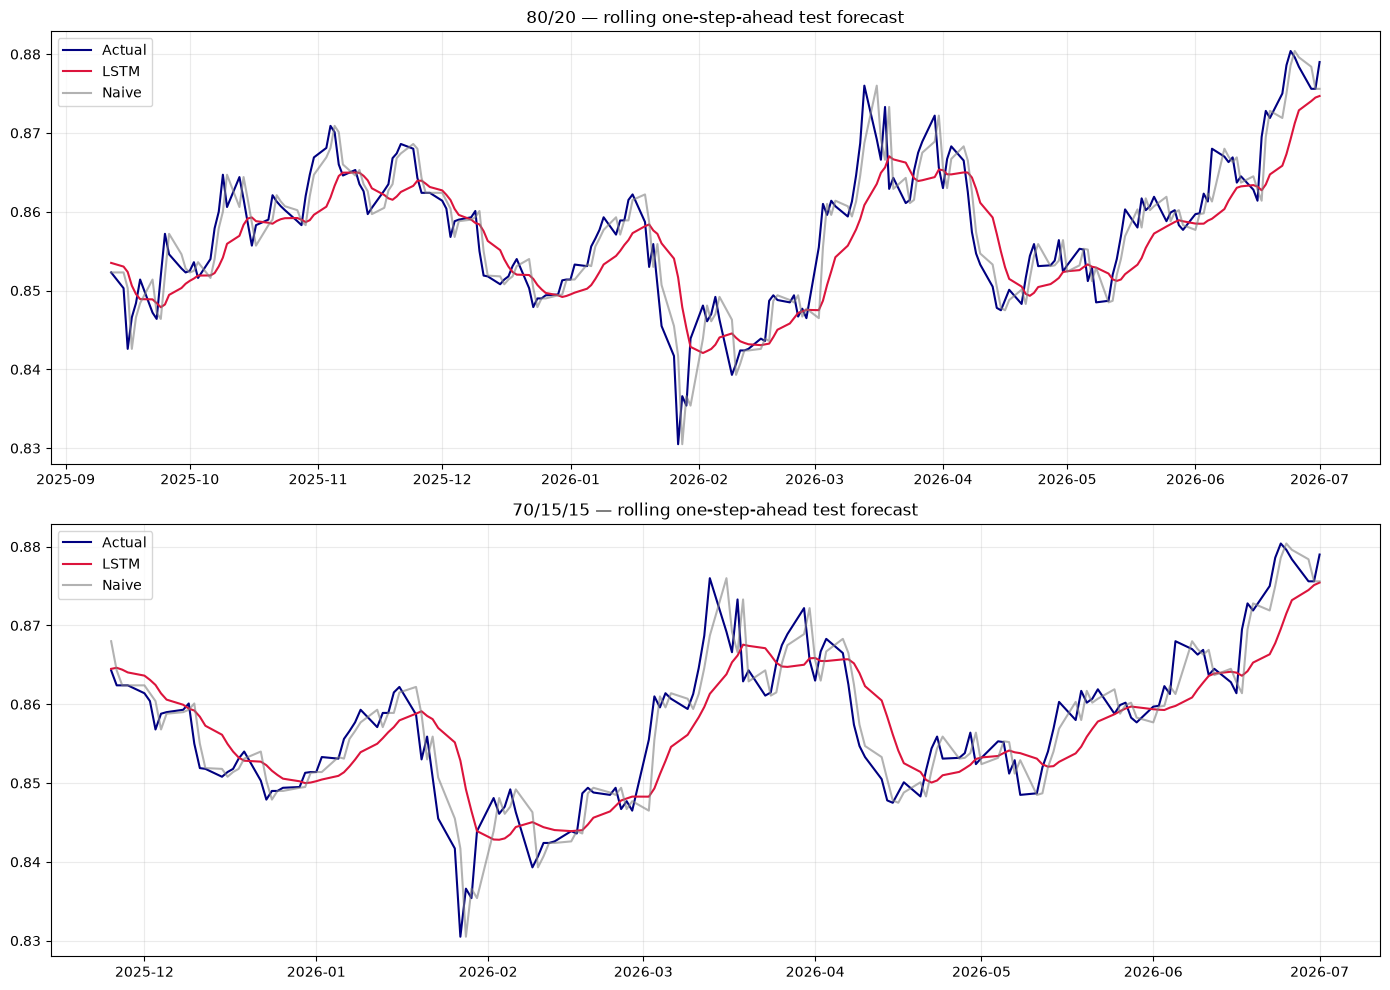

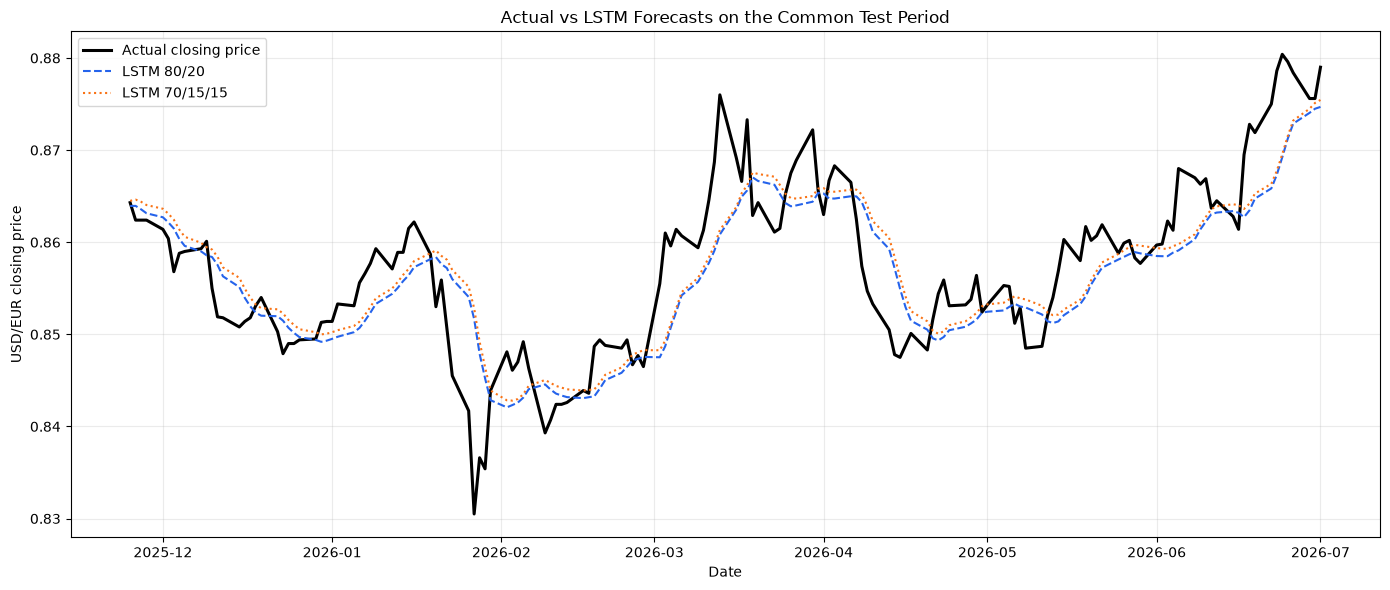

Common test period: 2025-11-25 to 2026-07-01


In [13]:
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

axes[0].plot(test_20.index, test_20, label="Actual", color="navy")
axes[0].plot(
    test_20.index,
    result_80["prediction"],
    label="LSTM",
    color="crimson",
)
axes[0].plot(
    test_20.index,
    naive_prediction_80,
    label="Naive",
    color="grey",
    alpha=0.6,
)
axes[0].set_title("80/20 — rolling one-step-ahead test forecast")
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].plot(test_15.index, test_15, label="Actual", color="navy")
axes[1].plot(
    test_15.index,
    result_70["prediction"],
    label="LSTM",
    color="crimson",
)
axes[1].plot(
    test_15.index,
    naive_prediction_70,
    label="Naive",
    color="grey",
    alpha=0.6,
)
axes[1].set_title("70/15/15 — rolling one-step-ahead test forecast")
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

# เปรียบเทียบ forecast ของทั้งสอง split บนช่วง Test ที่มีวันที่ตรงกัน
forecast_80_series = pd.Series(
    result_80["prediction"],
    index=test_20.index,
    name="LSTM 80/20",
)
forecast_70_series = pd.Series(
    result_70["prediction"],
    index=test_15.index,
    name="LSTM 70/15/15",
)

common_forecast_comparison = pd.concat(
    [
        price.rename("Actual closing price"),
        forecast_80_series,
        forecast_70_series,
    ],
    axis=1,
    join="inner",
).dropna()

plt.figure(figsize=(14, 6))
plt.plot(
    common_forecast_comparison.index,
    common_forecast_comparison["Actual closing price"],
    label="Actual closing price",
    color="black",
    linewidth=2.2,
)
plt.plot(
    common_forecast_comparison.index,
    common_forecast_comparison["LSTM 80/20"],
    label="LSTM 80/20",
    color="#2563eb",
    linewidth=1.5,
    linestyle="--",
)
plt.plot(
    common_forecast_comparison.index,
    common_forecast_comparison["LSTM 70/15/15"],
    label="LSTM 70/15/15",
    color="#f97316",
    linewidth=1.5,
    linestyle=":",
)
plt.title("Actual vs LSTM Forecasts on the Common Test Period")
plt.xlabel("Date")
plt.ylabel("USD/EUR closing price")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print(
    "Common test period:",
    common_forecast_comparison.index.min().date(),
    "to",
    common_forecast_comparison.index.max().date(),
)


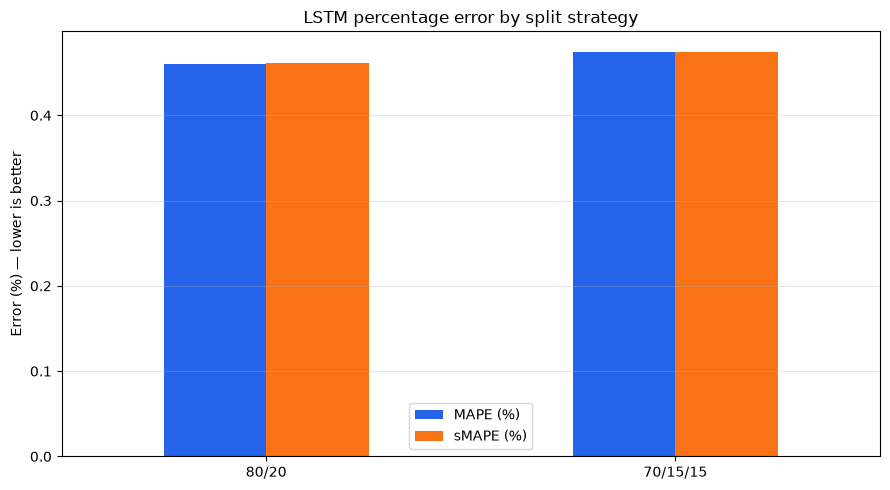

In [14]:
lstm_errors = (
    comparison.loc[comparison["Model"] == "LSTM"]
    .set_index("Strategy")[["MAPE (%)", "sMAPE (%)"]]
)

ax = lstm_errors.plot(
    kind="bar",
    figsize=(9, 5),
    color=["#2563eb", "#f97316"],
)
ax.set_title("LSTM percentage error by split strategy")
ax.set_ylabel("Error (%) — lower is better")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


## 7) LSTM diagnostics / assumptions

LSTM ไม่บังคับ stationarity, residual normality หรือ AR/MA roots แบบ ARIMA จึงตรวจสิ่งที่เหมาะกับ neural network:

- **No leakage:** split ตามเวลาและ scaler fit เฉพาะ training data
- **Overfitting heuristic:** validation RMSE / train RMSE ไม่เกิน 1.5
- **Residual bias:** one-sample t-test ควรมี `p > 0.05`
- **Residual independence:** Ljung–Box ควรมี `p > 0.05`
- **Normality และ ARCH:** เป็น diagnostics สำหรับ distribution/volatility ไม่ใช่ข้อบังคับของ point forecast


In [15]:
def lstm_diagnostics(
    strategy,
    residuals,
    overfit_ratio,
):
    residuals = np.asarray(residuals, dtype=float).reshape(-1)
    diagnostic_lag = min(10, max(1, len(residuals) // 5))

    _, bias_pvalue = ttest_1samp(residuals, popmean=0.0)
    ljung_pvalue = acorr_ljungbox(
        residuals,
        lags=[diagnostic_lag],
        return_df=True,
    )["lb_pvalue"].iloc[0]
    _, normality_pvalue = jarque_bera(residuals)
    _, arch_pvalue, _, _ = het_arch(
        residuals,
        nlags=diagnostic_lag,
    )

    return pd.DataFrame([
        {
            "Strategy": strategy,
            "Check": "Chronological split / no shuffle",
            "Value": 1.0,
            "Pass rule": "implemented",
            "Pass": True,
            "Type": "required",
        },
        {
            "Strategy": strategy,
            "Check": "Scaler fit on training only",
            "Value": 1.0,
            "Pass rule": "implemented",
            "Pass": True,
            "Type": "required",
        },
        {
            "Strategy": strategy,
            "Check": "Overfitting: validation/train RMSE ratio",
            "Value": overfit_ratio,
            "Pass rule": "ratio <= 1.50",
            "Pass": overfit_ratio <= 1.50,
            "Type": "heuristic",
        },
        {
            "Strategy": strategy,
            "Check": "Residual mean bias (t-test p-value)",
            "Value": bias_pvalue,
            "Pass rule": "p > 0.05",
            "Pass": bias_pvalue > 0.05,
            "Type": "diagnostic",
        },
        {
            "Strategy": strategy,
            "Check": f"Residual independence (Ljung-Box lag {diagnostic_lag})",
            "Value": ljung_pvalue,
            "Pass rule": "p > 0.05",
            "Pass": ljung_pvalue > 0.05,
            "Type": "diagnostic",
        },
        {
            "Strategy": strategy,
            "Check": "Residual normality (Jarque-Bera p-value)",
            "Value": normality_pvalue,
            "Pass rule": "p > 0.05",
            "Pass": normality_pvalue > 0.05,
            "Type": "optional diagnostic",
        },
        {
            "Strategy": strategy,
            "Check": f"Constant variance (ARCH LM lag {diagnostic_lag})",
            "Value": arch_pvalue,
            "Pass rule": "p > 0.05",
            "Pass": arch_pvalue > 0.05,
            "Type": "optional diagnostic",
        },
    ])


diagnostics = pd.concat([
    lstm_diagnostics(
        "80/20",
        result_80["residuals"],
        tuning_80["overfit_ratio"],
    ),
    lstm_diagnostics(
        "70/15/15",
        result_70["residuals"],
        tuning_70["overfit_ratio"],
    ),
], ignore_index=True)

diagnostics["Result"] = np.where(diagnostics["Pass"], "PASS", "FAIL")

display(
    diagnostics[
        ["Strategy", "Check", "Type", "Value", "Pass rule", "Result"]
    ].round({"Value": 6})
)

diagnostic_comparison = diagnostics.pivot(
    index="Check",
    columns="Strategy",
    values="Result",
)
display(diagnostic_comparison)


,Strategy,Check,Type,Value,Pass rule,Result
0,80/20,Chronological split / no shuffle,required,1.000000,implemented,PASS
1,80/20,Scaler fit on training only,required,1.000000,implemented,PASS
2,80/20,Overfitting: validation/train RMSE ratio,heuristic,1.468748,ratio <= 1.50,PASS
3,80/20,Residual mean bias (t-test p-value),diagnostic,0.000044,p > 0.05,FAIL
4,80/20,Residual independence (Ljung-Box lag 10),diagnostic,0.000000,p > 0.05,FAIL
5,80/20,Residual normality (Jarque-Bera p-value),optional diagnostic,0.000000,p > 0.05,FAIL
6,80/20,Constant variance (ARCH LM lag 10),optional diagnostic,0.000000,p > 0.05,FAIL
7,70/15/15,Chronological split / no shuffle,required,1.000000,implemented,PASS
8,70/15/15,Scaler fit on training only,required,1.000000,implemented,PASS
9,70/15/15,Overfitting: validation/train RMSE ratio,heuristic,1.412648,ratio <= 1.50,PASS


Strategy,70/15/15,80/20
Check,,
Chronological split / no shuffle,PASS,PASS
Constant variance (ARCH LM lag 10),FAIL,FAIL
Overfitting: validation/train RMSE ratio,PASS,PASS
Residual independence (Ljung-Box lag 10),FAIL,FAIL
Residual mean bias (t-test p-value),PASS,FAIL
Residual normality (Jarque-Bera p-value),FAIL,FAIL
Scaler fit on training only,PASS,PASS


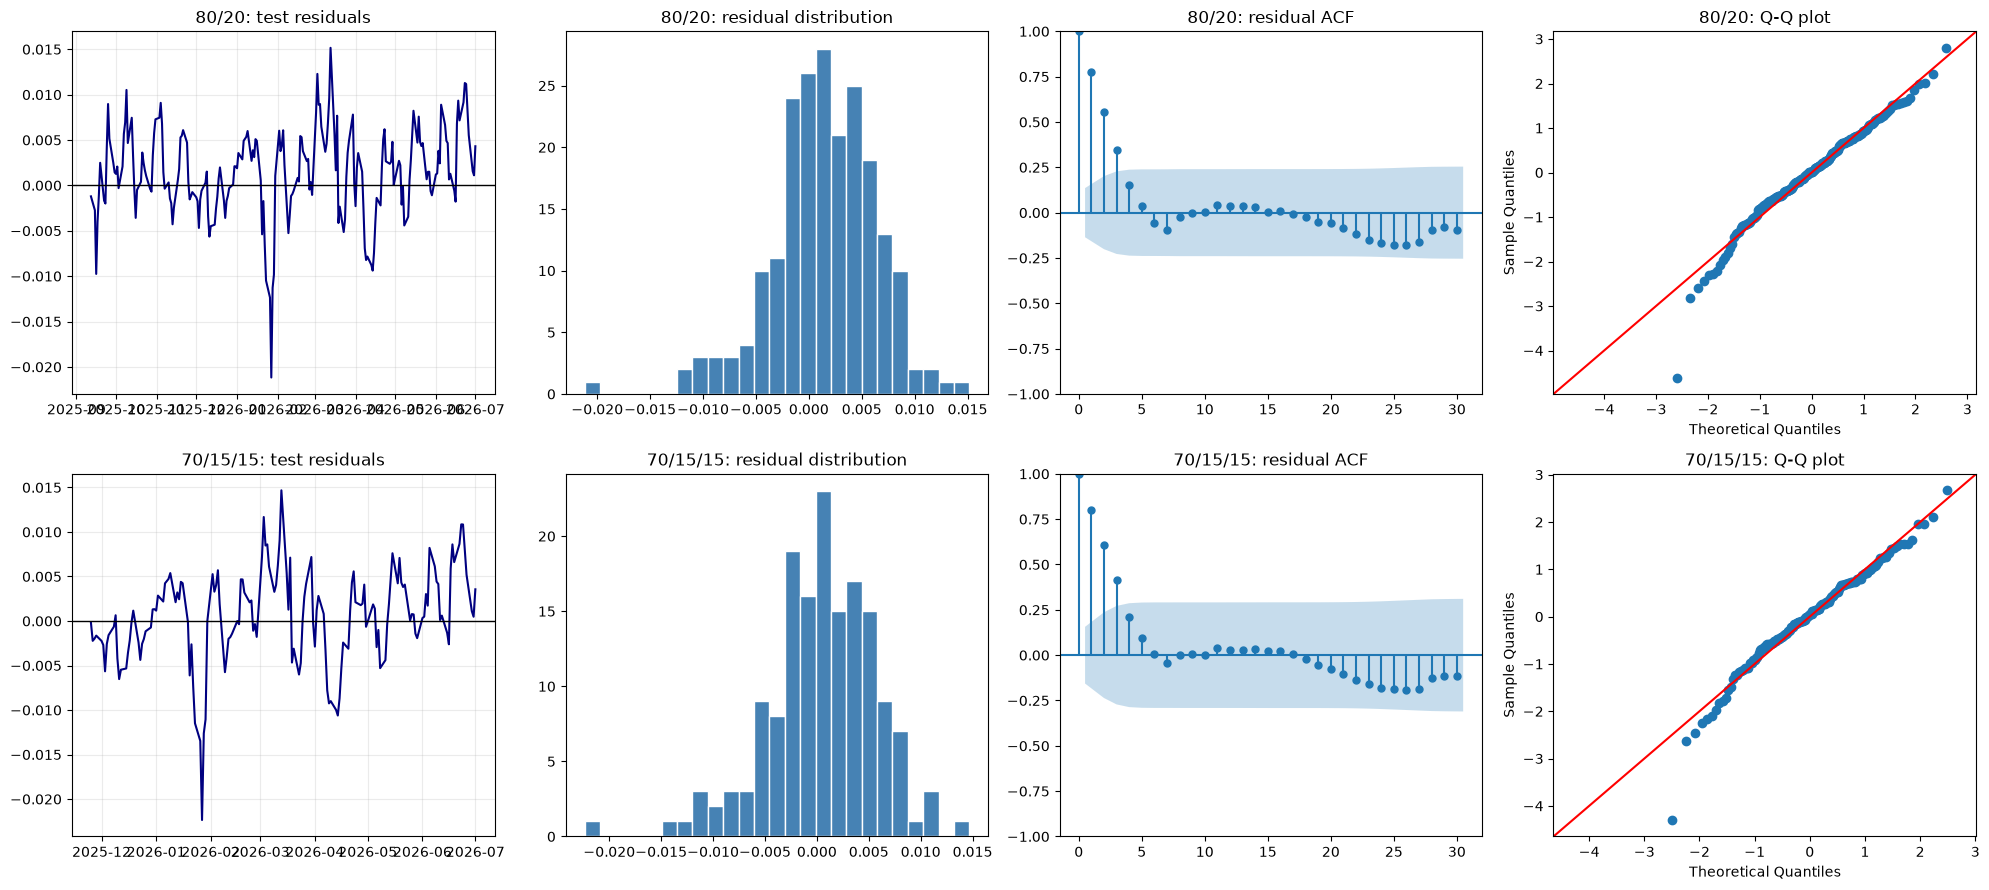

In [16]:
fig, axes = plt.subplots(2, 4, figsize=(20, 9))

residual_plot_data = [
    ("80/20", test_20.index, result_80["residuals"]),
    ("70/15/15", test_15.index, result_70["residuals"]),
]

for row, (strategy, dates, residuals) in enumerate(residual_plot_data):
    residuals = np.asarray(residuals)

    axes[row, 0].plot(dates, residuals, color="navy")
    axes[row, 0].axhline(0, color="black", linewidth=1)
    axes[row, 0].set_title(f"{strategy}: test residuals")
    axes[row, 0].grid(alpha=0.25)

    axes[row, 1].hist(
        residuals,
        bins=25,
        color="steelblue",
        edgecolor="white",
    )
    axes[row, 1].set_title(f"{strategy}: residual distribution")

    plot_acf(
        residuals,
        lags=min(30, max(1, len(residuals) // 4)),
        ax=axes[row, 2],
    )
    axes[row, 2].set_title(f"{strategy}: residual ACF")

    sm.qqplot(residuals, line="45", fit=True, ax=axes[row, 3])
    axes[row, 3].set_title(f"{strategy}: Q-Q plot")

plt.tight_layout()
plt.show()


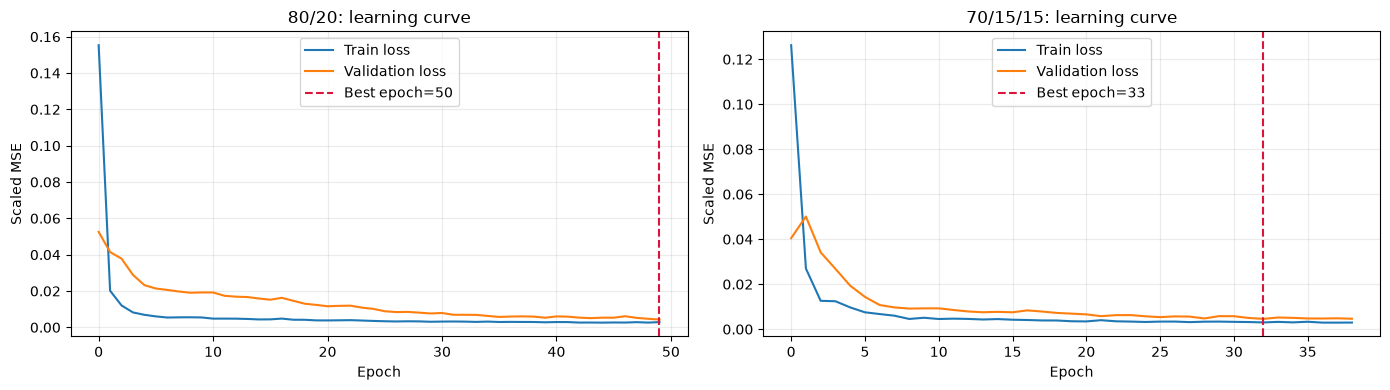

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

for ax, strategy, tuning in [
    (axes[0], "80/20", tuning_80),
    (axes[1], "70/15/15", tuning_70),
]:
    ax.plot(tuning["history"]["loss"], label="Train loss")
    ax.plot(tuning["history"]["val_loss"], label="Validation loss")
    ax.axvline(
        tuning["best_epoch"] - 1,
        color="crimson",
        linestyle="--",
        label=f"Best epoch={tuning['best_epoch']}",
    )
    ax.set_title(f"{strategy}: learning curve")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Scaled MSE")
    ax.legend()
    ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()


## 8) Final one-day forecast

หลังประเมินเสร็จ สร้างโมเดลใหม่ด้วยข้อมูลทั้งหมดและจำนวน epochs ที่เลือกไว้ แล้วรายงาน forecast จาก configuration ของทั้งสองกลยุทธ์เพื่อไม่เลือกผู้ชนะจาก test set อย่างไม่โปร่งใส


In [18]:
def fit_all_and_forecast_next(
    full_series,
    config,
    epochs,
    seed,
):
    scaler = MinMaxScaler()
    values = full_series.to_numpy().reshape(-1, 1)
    scaled = scaler.fit_transform(values)

    X, y = make_train_sequences(scaled, config["lookback"])
    model = build_lstm_model(**config, seed=seed)
    model.fit(
        X,
        y,
        epochs=max(1, epochs),
        batch_size=BATCH_SIZE,
        shuffle=False,
        verbose=0,
    )

    last_window = scaled[-config["lookback"]:].reshape(
        1,
        config["lookback"],
        1,
    )
    forecast_scaled = model.predict(last_window, verbose=0)
    forecast = float(scaler.inverse_transform(forecast_scaled)[0, 0])
    return model, scaler, forecast


final_model_80, final_scaler_80, forecast_80 = fit_all_and_forecast_next(
    price,
    BEST_CONFIG_80,
    tuning_80["best_epoch"],
    seed=SEED + 900,
)
final_model_70, final_scaler_70, forecast_70 = fit_all_and_forecast_next(
    price,
    BEST_CONFIG_70,
    tuning_70["best_epoch"],
    seed=SEED + 901,
)

next_date = price.index[-1] + pd.offsets.BDay(1)

next_day_forecasts = pd.DataFrame([
    {
        "Source strategy": "80/20",
        "Forecast date": next_date.date(),
        "Last observed price": price.iloc[-1],
        "LSTM forecast": forecast_80,
        "Change from last price (%)": (
            (forecast_80 / price.iloc[-1]) - 1
        ) * 100,
        "Config": str(BEST_CONFIG_80),
        "Epochs": tuning_80["best_epoch"],
    },
    {
        "Source strategy": "70/15/15",
        "Forecast date": next_date.date(),
        "Last observed price": price.iloc[-1],
        "LSTM forecast": forecast_70,
        "Change from last price (%)": (
            (forecast_70 / price.iloc[-1]) - 1
        ) * 100,
        "Config": str(BEST_CONFIG_70),
        "Epochs": tuning_70["best_epoch"],
    },
])

display(next_day_forecasts.round(6))
print("หมายเหตุ: วันที่ forecast อิงจากวันสุดท้ายในไฟล์ข้อมูล ไม่ใช่วันที่ปัจจุบัน")


,Source strategy,Forecast date,Last observed price,LSTM forecast,Change from last price (%),Config,Epochs
0,80/20,2026-07-02,0.879,0.874063,-0.561612,"{'lookback': 30, 'units': 32, 'dropout': 0.1}",50
1,70/15/15,2026-07-02,0.879,0.872610,-0.726972,"{'lookback': 30, 'units': 32, 'dropout': 0.1}",33


หมายเหตุ: วันที่ forecast อิงจากวันสุดท้ายในไฟล์ข้อมูล ไม่ใช่วันที่ปัจจุบัน
